# Tugas 3 — Segmentasi Pelanggan (*Clustering*)

Notebook ini menjalankan pipeline Tugas 3 langkah demi langkah dengan kode yang sama seperti
`python kode/run_all.py --stages clustering`. Setiap butir menjalankan modulnya di
`kode/src/clustering/`, lalu menampilkan ringkasan angka dari `kode/results/` dan grafik dari
`kode/figures/`.

| Butir | Isi | Modul | Penanggung jawab |
| --- | --- | --- | --- |
| 3a | Prapemrosesan dan deteksi awal akun bot | `preprocess.py` | Firdaus Arif Ramadhani |
| 3b | Seleksi fitur dan pembobotan blok | `features.py` | Firdaus Arif Ramadhani |
| 3c | Perbandingan metode *clustering* | `models.py` | Rainaldi Pakpahan |
| 3d | Pemilihan jumlah klaster K | `models.py` | Rainaldi Pakpahan |
| 3e | Stabilitas lewat *subsampling* | `stability.py` | Rainaldi Pakpahan |
| 3f | Profil segmen dan aksi pemasaran | `analysis.py` | Rainaldi Pakpahan |
| 3g | Anomali (`cluster = -1`) dan `cluster.csv` | `analysis.py` | Rainaldi Pakpahan |

Penilaian memakai ARI terhadap segmen acuan tersembunyi; label `-1` menandai anomali.
Seluruh langkah memakai `SEED = 42`.

## Persiapan

Sel ini menyiapkan *path*, *seed* global, dan dua pembantu: `baca_hasil()` untuk membaca JSON hasil
dan `tampilkan_gambar()` untuk menampilkan grafik. Data dibaca dari folder `data/` di *root* repositori
(atau dari variabel lingkungan `UTS_ML_DATA_DIR`).

In [1]:
import json
import sys
import warnings
from io import BytesIO
from pathlib import Path

import matplotlib

# Peringatan informatif yang tidak memengaruhi hasil (deprecation pandas, tqdm, format keluaran SHAP)
warnings.filterwarnings("ignore", message="Constructing a Categorical with a dtype")
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="LightGBM binary classifier with TreeExplainer")

# Backend non-interaktif: grafik disimpan ke kode/figures/ lalu ditampilkan dari berkasnya
matplotlib.use("Agg")

import pandas as pd  # noqa: E402
from IPython.display import Image, Markdown, display  # noqa: E402
from PIL import Image as PILImage  # noqa: E402

# Notebook dijalankan dari kode/notebooks/; folder kode/ dimasukkan ke sys.path
KODE_DIR = Path.cwd().resolve()
if KODE_DIR.name == "notebooks":
    KODE_DIR = KODE_DIR.parent
if str(KODE_DIR) not in sys.path:
    sys.path.insert(0, str(KODE_DIR))

from src.config import FIGURES_DIR, REPO_ROOT, RESULTS_DIR, SEED  # noqa: E402
from src.utils import set_global_seed  # noqa: E402

set_global_seed(SEED)
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)


def baca_hasil(nama: str) -> dict:
    """Baca berkas JSON hasil eksperimen dari kode/results/."""
    return json.loads((RESULTS_DIR / nama).read_text(encoding="utf-8"))


def tampilkan_gambar(nama: str, lebar: int = 1100) -> None:
    """Tampilkan grafik dari kode/figures/ (diperkecil agar notebook tetap ringan)."""
    gambar = PILImage.open(FIGURES_DIR / nama)
    if gambar.width > lebar:
        tinggi = round(gambar.height * lebar / gambar.width)
        gambar = gambar.resize((lebar, tinggi), PILImage.LANCZOS)
    buffer = BytesIO()
    gambar.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


def tabel_metrik(kamus: dict, kolom: list[str] | None = None) -> pd.DataFrame:
    """Ubah {nama: {metrik: nilai}} menjadi tabel (baris = nama, kolom = metrik)."""
    df = pd.DataFrame.from_dict(kamus, orient="index")
    return df[kolom] if kolom else df


print(f"Folder kode : {KODE_DIR.relative_to(REPO_ROOT)}/")
print(f"Seed global : {SEED}")

Folder kode : kode/
Seed global : 42


## 3a. Prapemrosesan

*Penanggung jawab: Firdaus Arif Ramadhani*

1. **Deteksi awal akun bot** sebelum penskalaan: GMM 2 komponen pada empat indikator aktivitas
   (`sesi_per_minggu`, `durasi_sesi_menit`, `klik_iklan_30h`, `wishlist`), agar nilai ekstrem bot tidak
   mengganggu skala, imputasi, dan sentroid.
2. **Transformasi sesuai jenis variabel:** `log` setelah *winsorizing* untuk variabel positif yang
   menceng, `log1p` untuk variabel cacah, `logit` untuk proporsi, standardisasi untuk `umur`.
3. **Imputasi `rata2_keranjang`** yang kosong (seluruhnya pelanggan dengan `frekuensi_90h = 0`) memakai
   Ridge pada skala log.
4. **Data komposisional** (`porsi_<kategori>` dan `porsi_jam_*`) diubah dengan *centered log-ratio* (CLR).
5. **Kategori:** `perangkat` menjadi indikator `is_ios`; `kota_tier` tidak membawa sinyal.

In [2]:
%run ../src/clustering/preprocess.py --save-json

[START] Task 3a: Preprocessing & Data Quality Audit


Dataset       : 120,000 baris x 60 kolom (anomali bot pra-skala: 1,800 = 1.50%)
Nilai hilang  : rata2_keranjang=6,647 (5.62% non-bot, 100% frekuensi_90h==0), Ridge R^2=0.3266
Jurang nol    : naif max kemurnian f0=100.0% (konsentrasi 100.0%) -> kanonik=21.5% (ARI naif vs kanonik=0.6527)
Kategorikal   : kota_tier Kruskal p=0.2478 (noise), perangkat p=0.00e+00, android vs web p=0.2690
Figur         : task3_3a_preprocessing.png
[DONE]  Task 3a: Preprocessing & Data Quality Audit (9.35s)


**Deteksi awal akun bot**

,nilai
n_total,120000
n_bot,1800
n_normal,118200
pct_bot,1.5
bot_min_posterior,1.0
normal_max_posterior,0.0


**Kemencengan (*skewness*) sebelum dan sesudah transformasi**

,sebelum,sesudah
frekuensi_90h,3.5352,-0.1892
item_per_pesanan,3.4840,0.7579
lama_member_bulan,3.2717,-0.5220
persen_cod,0.7847,0.0734
persen_flash_sale,0.3571,0.0832
persen_paylater,1.3200,0.6344
persen_voucher,-0.0088,0.0350
rata2_keranjang,3.5683,0.2924
recency_hari,7.9554,0.5846
retur_90h,2.8214,0.8124


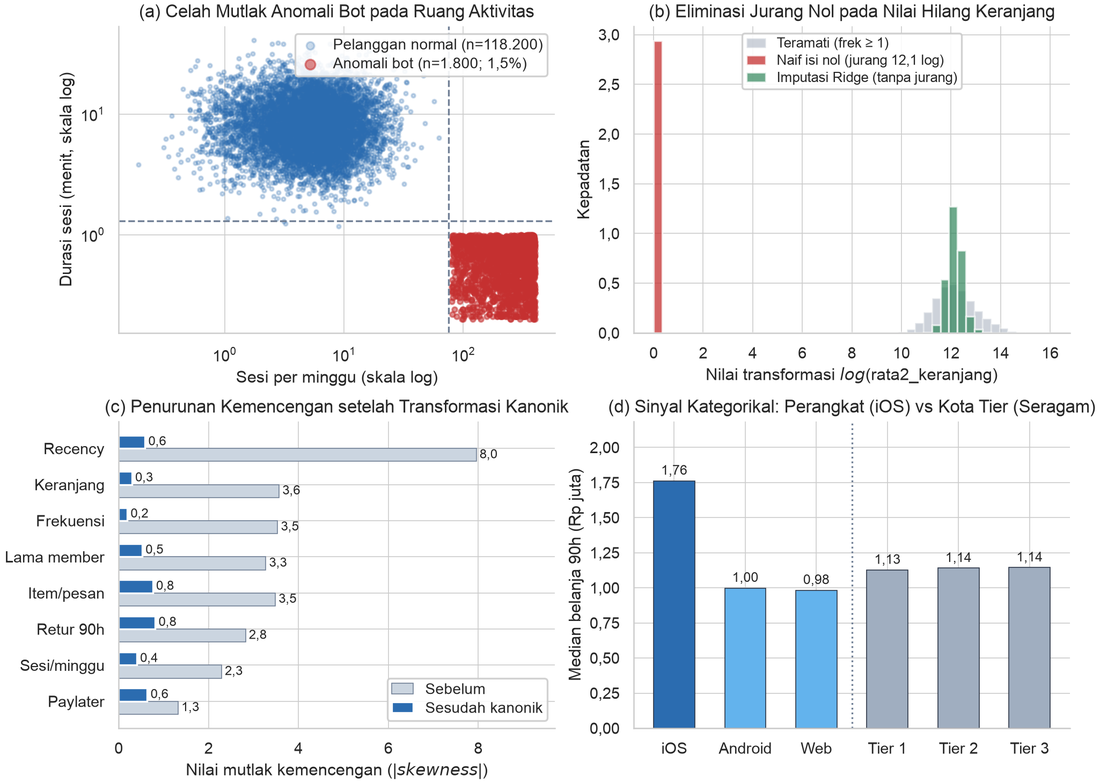

In [3]:
pra = baca_hasil("task3_preprocess.json")
bot = pra["bot_prescreening"]
display(Markdown("**Deteksi awal akun bot**"))
display(pd.Series({k: bot[k] for k in ("n_total", "n_bot", "n_normal", "pct_bot",
                                         "bot_min_posterior", "normal_max_posterior")},
                  name="nilai", dtype=object).to_frame())
display(Markdown("**Kemencengan (*skewness*) sebelum dan sesudah transformasi**"))
transformasi = pra["canonical_transform"]
display(pd.DataFrame({"sebelum": transformasi["skew_before"], "sesudah": transformasi["skew_after"]}))
tampilkan_gambar("task3_3a_preprocessing.png")

## 3b. Seleksi Fitur dan Pembobotan Blok

*Penanggung jawab: Firdaus Arif Ramadhani*

Seluruh 59 fitur kandidat disaring pada pelanggan non-bot dengan tiga bukti independen: koherensi
multivariat Spearman, prediktabilitas silang *out-of-fold* (Ridge R²), dan koefisien bimodalitas Sarle.
Fitur *noise*, redundan, dan kategori berprofil datar dibuang; fitur terpilih diberi bobot per blok
(perilaku inti, CLR waktu belanja, `is_ios`, CLR kategori). Ablasi lima konfigurasi pada K = 6
membuktikan dampaknya.

In [4]:
%run ../src/clustering/features.py --run-ablation --save-json

[START] Task 3b: Feature Selection & Block Weighting


Figur         : task3_3b_feature_selection.png
Seleksi fitur : 59 kandidat -> 26D terbobot -> PCA-12 (varians kumulatif 80.5%)
Pangsa varians blok 26D: {'core_behavior_13': 71.9, 'time_clr_3': 16.6, 'device_ios_1': 1.4, 'category_clr_9': 10.1}
Ablasi K=6:
  all_59_raw               (61D): KM_sil=0.0484, GMM_sil=0.0036, KM-GMM_ARI=0.3291, GMM_stab=0.2792
  drop_n15_only            (46D): KM_sil=0.0528, GMM_sil=0.0414, KM-GMM_ARI=0.2466, GMM_stab=0.4151
  selected_26d_unweighted  (26D): KM_sil=0.0896, GMM_sil=0.0761, KM-GMM_ARI=0.7658, GMM_stab=0.8162
  selected_26d_weighted    (26D): KM_sil=0.1125, GMM_sil=0.1095, KM-GMM_ARI=0.8339, GMM_stab=0.9995
  selected_pca12           (12D): KM_sil=0.1470, GMM_sil=0.1448, KM-GMM_ARI=0.8482, GMM_stab=0.9996
[DONE]  Task 3b: Feature Selection & Block Weighting (47.98s)


**Status setiap kelompok fitur**

,count,max_spearman_sum_r2,max_oof_r2,max_sarle_bimodality,features
dropped_anonymous_noise,15,0.0016,0.0000,0.6834,"n01, n02, n03, n04, n05, n06, n07, n08, n09, n..."
dropped_bot_only_detector,3,0.0010,0.0000,0.5318,"durasi_sesi_menit, wishlist, klik_iklan_30h"
dropped_low_signal_category,7,0.0146,0.0057,0.5954,"porsi_olahraga, porsi_otomotif, porsi_kesehata..."
dropped_named_noise,3,0.0012,0.0000,0.6571,"rating_beri_rata2, kota_tier, jumlah_alamat"
dropped_redundant,4,1.9601,0.9563,0.4892,"belanja_90h, rasio_konversi, belanja_30h, frek..."
selected_category_clr,9,0.2503,0.1033,0.6125,"porsi_fashion, porsi_makanan_minuman, porsi_ke..."
selected_core_behavior,13,0.8946,0.5801,0.7187,"frekuensi_90h, ulasan_90h, persen_voucher, per..."
selected_device_ios,1,0.1908,0.0965,1.0000,perangkat
selected_time_clr,4,0.4304,0.1785,0.5374,"porsi_jam_malam, porsi_jam_pagi, porsi_jam_sia..."


**Ablasi konfigurasi fitur pada K = 6**

,gmm_mean_max_posterior,gmm_seed_stability_ari,gmm_silhouette,km_calinski_harabasz,km_davies_bouldin,km_gmm_agreement_ari,km_seed_stability_ari,km_silhouette,n_dims
all_59_raw,0.9519,0.2792,0.0036,945.9869,3.6267,0.3291,0.9983,0.0484,61
drop_n15_only,0.9647,0.4151,0.0414,1294.6203,3.3043,0.2466,0.7180,0.0528,46
selected_26d_unweighted,0.9218,0.8162,0.0761,1940.9487,2.7269,0.7658,0.9994,0.0896,26
selected_26d_weighted,0.9505,0.9995,0.1095,2742.1139,2.3561,0.8339,0.9987,0.1125,26
selected_pca12,0.9354,0.9996,0.1448,3803.8437,1.9856,0.8482,0.9984,0.1470,12


Bobot blok: {'category_clr_top9': 0.45, 'core_behavior': 1.0, 'device_ios': 0.5, 'time_clr': 1.0}


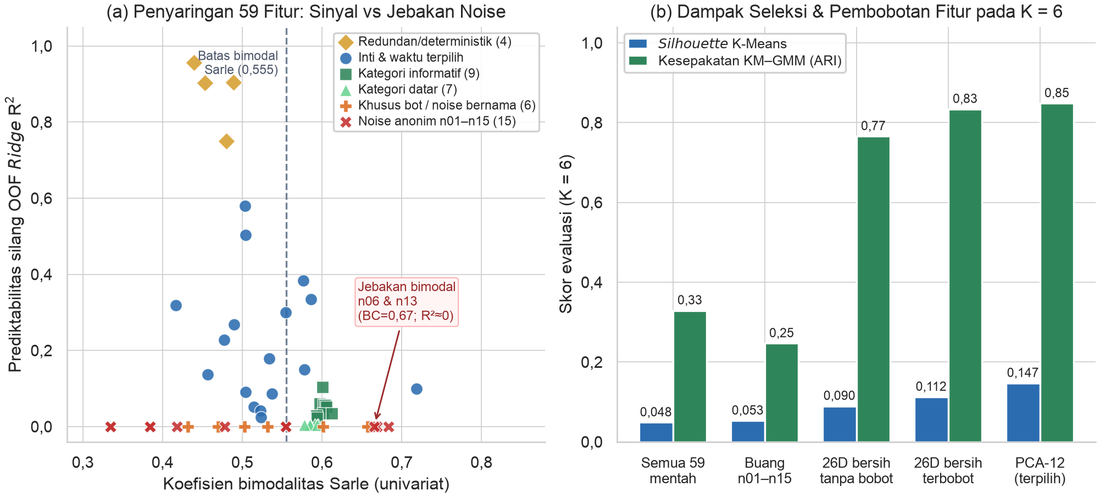

In [5]:
fitur = baca_hasil("task3_features.json")
status = pd.DataFrame.from_dict(fitur["status_summary"], orient="index")
status["features"] = status["features"].map(", ".join)
display(Markdown("**Status setiap kelompok fitur**"))
display(status[["count", "max_spearman_sum_r2", "max_oof_r2", "max_sarle_bimodality", "features"]])
display(Markdown("**Ablasi konfigurasi fitur pada K = 6**"))
display(tabel_metrik(fitur["ablation_k6"]).drop(columns=["gmm_sizes_pct"], errors="ignore"))
print("Bobot blok:", fitur["block_weights"])
tampilkan_gambar("task3_3b_feature_selection.png")

## 3c. Perbandingan Metode *Clustering*

*Penanggung jawab: Rainaldi Pakpahan*

Lima keluarga algoritma dibandingkan pada K = 6 di ruang fitur hasil 3a–3b: *Gaussian mixture model*
(kovarians penuh 26D dan PCA-12, diagonal PCA-12), K-Means, *agglomerative* Ward, BIRCH, dan HDBSCAN
(untuk menguji apakah ada struktur kepadatan). Kesepakatan antarmetode diukur dengan ARI.

Modul `models.py` sekaligus menjalankan pemindaian K untuk butir 3d.

In [6]:
%run ../src/clustering/models.py --save-json

[START] Tasks 3c & 3d: Methods Comparison & K Selection


=== Ringkasan Pemindaian K (PCA-12) ===
  K=2: BIC= 1181936.6 (dBIC=    +0.0) | Sil_KM=0.1522 Sil_GM=0.1457 | Gap=1.5369±0.0019 | ARI_KG=0.3569 Stab_GM=0.9987
  K=3: BIC= 1170253.3 (dBIC=-11683.2) | Sil_KM=0.1727 Sil_GM=0.1711 | Gap=1.6110±0.0021 | ARI_KG=0.9062 Stab_GM=1.0000
  K=4: BIC= 1164813.6 (dBIC= -5439.7) | Sil_KM=0.1546 Sil_GM=0.1512 | Gap=1.6244±0.0029 | ARI_KG=0.5707 Stab_GM=0.8281
  K=5: BIC= 1161519.5 (dBIC= -3294.1) | Sil_KM=0.1421 Sil_GM=0.1408 | Gap=1.6433±0.0023 | ARI_KG=0.8523 Stab_GM=0.9950
  K=6: BIC= 1159870.0 (dBIC= -1649.5) | Sil_KM=0.1484 Sil_GM=0.1471 | Gap=1.6666±0.0039 | ARI_KG=0.8475 Stab_GM=0.9994
  K=7: BIC= 1159824.0 (dBIC=   -45.9) | Sil_KM=0.1403 Sil_GM=0.1404 | Gap=1.6714±0.0028 | ARI_KG=0.8543 Stab_GM=0.9928
  K=8: BIC= 1159822.1 (dBIC=    -2.0) | Sil_KM=0.1256 Sil_GM=0.1206 | Gap=1.6692±0.0034 | ARI_KG=0.7824 Stab_GM=0.1105

=== Perbandingan Metode (K=6) ===
  GMM_full_26D   : Sil_P12=0.1411, CH= 3663.7, DB=2.012, Cons_ARI=0.8296, post=0.9505
  GMM_

In [7]:
model = baca_hasil("task3_models.json")
metode = tabel_metrik(model["method_comparison_k6"]["partition_methods"])
display(metode.drop(columns=["sizes_pct"], errors="ignore").sort_values("mean_consensus_ari", ascending=False))
print("Metode terpilih:", model["selected_method"])

,calinski_harabasz_pca12,davies_bouldin_pca12,mean_consensus_ari,n_clusters,silhouette_26d,silhouette_pca12,mean_max_posterior
Ward_PCA12,3786.7319,1.9499,0.8672,6,0.1135,0.1482,NaN
KMeans_26D,3801.7401,1.9840,0.8601,6,0.1124,0.1470,NaN
KMeans_PCA12,3803.8437,1.9856,0.8546,6,0.1122,0.1470,NaN
GMM_full_PCA12,3713.1915,1.9808,0.8521,6,0.1109,0.1448,0.9354
GMM_diag_PCA12,3712.5023,1.9148,0.8331,6,0.1112,0.1451,0.9100
GMM_full_26D,3663.7365,2.0124,0.8296,6,0.1095,0.1411,0.9505
BIRCH_PCA12,3407.5371,2.0981,0.7514,6,0.0953,0.1246,NaN


Metode terpilih: GMM_full_26D


## 3d. Pemilihan Jumlah Klaster K

*Penanggung jawab: Rainaldi Pakpahan*

Rentang K = 2..8 dinilai dengan empat kriteria independen: BIC GMM beserta penurunannya (ΔBIC),
*silhouette* (K-Means dan GMM), *gap statistic*, serta stabilitas antar-*seed* dan kesepakatan
K-Means vs GMM.

,gmm_bic,gmm_dbic,gmm_silhouette,gap,gap_gain,gmm_seed_stability_ari,km_gmm_agreement_ari,gmm_mean_max_posterior
k,,,,,,,,
2,1.1819e+06,0.0000,0.1457,1.5369,0.0000,0.9987,0.3569,0.9776
3,1.1703e+06,-11683.2335,0.1711,1.6110,0.0741,1.0000,0.9062,0.9709
4,1.1648e+06,-5439.6934,0.1512,1.6244,0.0135,0.8281,0.5707,0.9498
5,1.1615e+06,-3294.1491,0.1408,1.6433,0.0189,0.9950,0.8523,0.9327
6,1.1599e+06,-1649.5172,0.1471,1.6666,0.0233,0.9994,0.8475,0.9330
7,1.1598e+06,-45.9359,0.1404,1.6714,0.0048,0.9928,0.8543,0.9016
8,1.1598e+06,-1.9663,0.1206,1.6692,-0.0022,0.1105,0.7824,0.8433


K terpilih: 6
Alasan: K=6 dipilih karena pertemuan empat kriteria independen: siku penurunan BIC (anjlok >35x dari K=6 ke K=7 lalu mendatar), puncak lokal Silhouette K-Means & GMM, lonjakan marginal tertinggi Gap Statistic, stabilitas seed GMM >0,999, dan kesepakatan antar-metode tinggi (ARI 0,83–0,89). GMM Full Covariance pada 26D terpilih dibanding K-Means/Ward karena memodelkan kovarians elips dan bobot proporsi tak-sama tiap segmen (mean max posterior ~0,95).


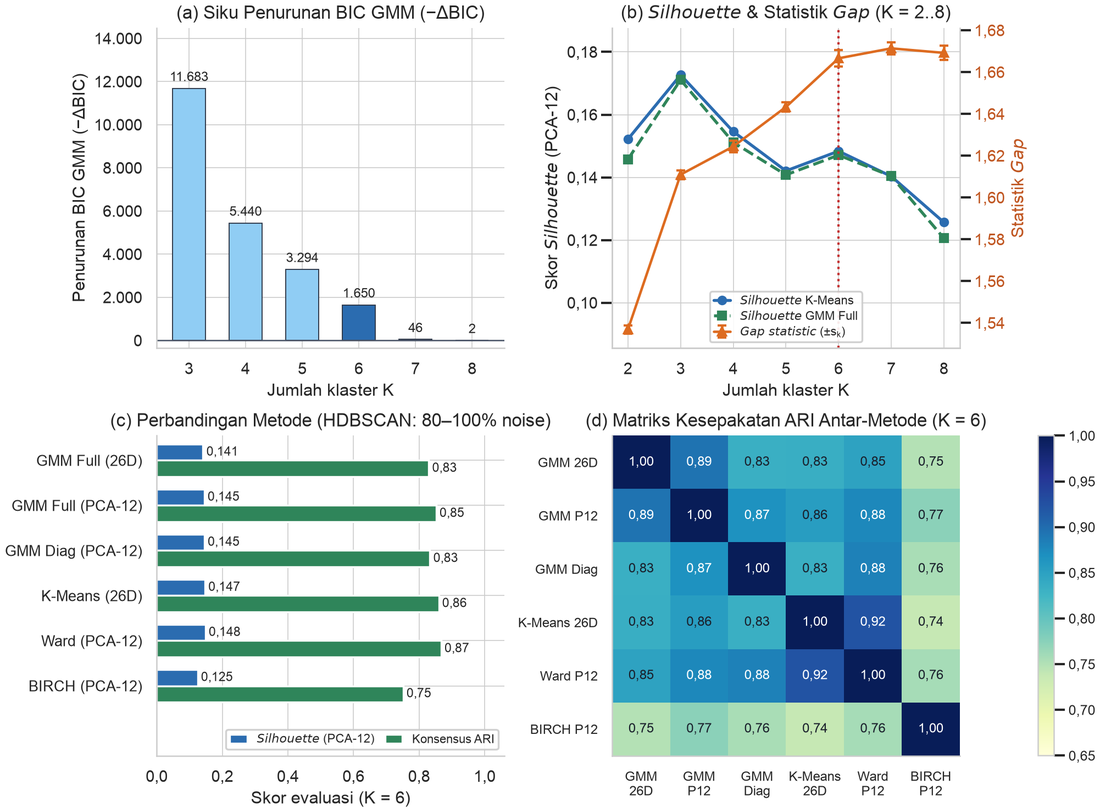

In [8]:
pindai = pd.DataFrame(model["k_selection"]["k_scan"]).set_index("k")
display(pindai[[
    "gmm_bic", "gmm_dbic", "gmm_silhouette", "gap", "gap_gain",
    "gmm_seed_stability_ari", "km_gmm_agreement_ari", "gmm_mean_max_posterior",
]])
print(f"K terpilih: {model['selected_k']}")
print("Alasan:", model["selection_rationale"])
tampilkan_gambar("task3_3cd_methods_and_k.png")

## 3e. Stabilitas Lewat *Subsampling*

*Penanggung jawab: Rainaldi Pakpahan*

Dua skema *subsampling* 80% tanpa pengembalian:

1. Stabilitas lintas K ∈ {4, …, 8} untuk GMM dan K-Means (ARI berpasangan pada observasi yang sama).
2. Stabilitas model final (GMM kovarians penuh 26D, K = 6) beserta Jaccard per segmen setelah
   penyelarasan label dengan algoritma Hungaria.

In [9]:
%run ../src/clustering/stability.py --save-json

[START] Task 3e: Clustering Stability Evaluation


=== Stabilitas Subsampling 80% Lintas K (66 pasangan ARI) ===
  K=4: GMM_ARI=0.8340±0.1129 (min=0.6023) | KM_ARI=0.9935±0.0020 (min=0.9889)
  K=5: GMM_ARI=0.8703±0.0969 (min=0.7291) | KM_ARI=0.9875±0.0033 (min=0.9794)
  K=6: GMM_ARI=0.9830±0.0021 (min=0.9770) | KM_ARI=0.9886±0.0024 (min=0.9827)
  K=7: GMM_ARI=0.7950±0.3237 (min=0.0896) | KM_ARI=0.9852±0.0021 (min=0.9805)
  K=8: GMM_ARI=0.5395±0.4163 (min=0.1048) | KM_ARI=0.9689±0.0075 (min=0.9526)

Model final (GMM Full 26D, K=6, 105 pasangan): Pairwise ARI=0.9836±0.0010 (median=0.9836, min=0.9808)
Jaccard per segmen:
  Pasif / Dormant COD                : 0.9951 ± 0.0005 (min=0.9942)
  Keluarga Pembeli Rutin Pagi        : 0.9920 ± 0.0008 (min=0.9907)
  Premium / Affluent iOS             : 0.9904 ± 0.0013 (min=0.9881)
  Pemburu Promo & Flash Sale Malam   : 0.9891 ± 0.0010 (min=0.9862)
  Member Baru Window-Shopper         : 0.9795 ± 0.0039 (min=0.9731)
  Impulsif PayLater & Retur Tinggi   : 0.9787 ± 0.0030 (min=0.9699)
Figur         : t

**Rata-rata ARI berpasangan per K**

,gmm_full_pca12,kmeans_pca12
4,0.8340,0.9935
5,0.8703,0.9875
6,0.9830,0.9886
7,0.7950,0.9852
8,0.5395,0.9689


**Model final GMM_full_26D (K = 6, 15 subsampel)**

,mean,std,min,max
ARI berpasangan,0.9836,0.0010,0.9808,0.9856
ARI vs acuan,0.9883,0.0007,0.9866,0.9893


,max_jaccard,mean_jaccard,min_jaccard,std_jaccard
Impulsif PayLater & Retur Tinggi,0.9827,0.9787,0.9699,0.0030
Keluarga Pembeli Rutin Pagi,0.9935,0.9920,0.9907,0.0008
Member Baru Window-Shopper,0.9858,0.9795,0.9731,0.0039
Pasif / Dormant COD,0.9959,0.9951,0.9942,0.0005
Pemburu Promo & Flash Sale Malam,0.9904,0.9891,0.9862,0.0010
Premium / Affluent iOS,0.9925,0.9904,0.9881,0.0013


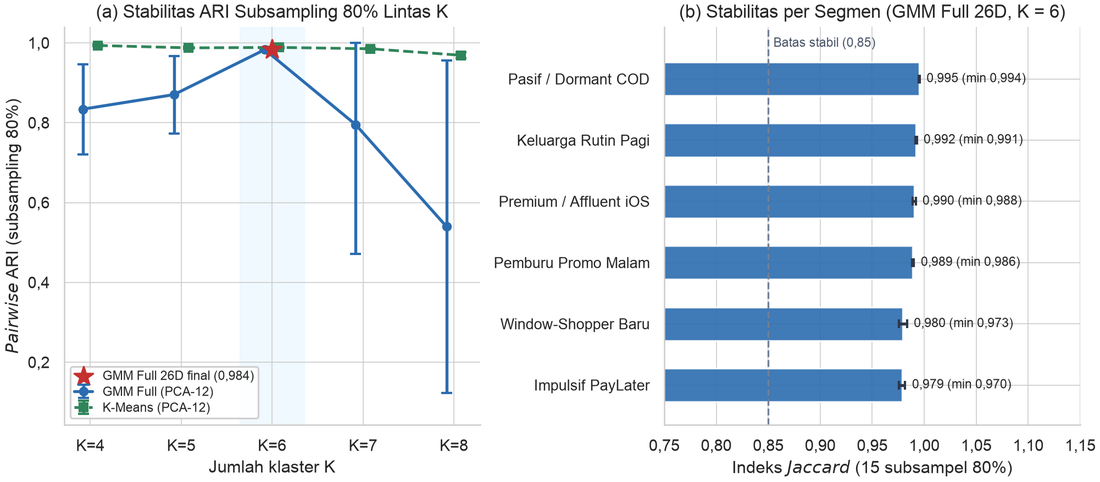

In [10]:
stabil = baca_hasil("task3_stability.json")
lintas_k = stabil["stability_across_k"]
display(Markdown("**Rata-rata ARI berpasangan per K**"))
display(pd.DataFrame({
    nama: {int(k): v["mean"] for k, v in lintas_k[nama].items()}
    for nama in ("gmm_full_pca12", "kmeans_pca12")
}))
final = stabil["final_model_stability"]
display(Markdown(f"**Model final {final['model']} (K = {final['k']}, {final['n_runs']} subsampel)**"))
display(tabel_metrik({
    "ARI berpasangan": final["pairwise_ari"],
    "ARI vs acuan": final["ari_vs_reference"],
}, ["mean", "std", "min", "max"]))
display(tabel_metrik(final["per_segment_jaccard"]))
tampilkan_gambar("task3_3e_stability.png")

## 3f. Profil Segmen dan Aksi Pemasaran

*Penanggung jawab: Rainaldi Pakpahan*

Model produksi (GMM kovarians penuh, 26D terbobot, K = 6) dilatih pada seluruh pelanggan non-bot.
ID segmen dipetakan secara deterministik ke 0..5, lalu setiap segmen diringkas profil perilakunya,
pangsa omzetnya, dan satu aksi pemasaran yang terukur.

Modul `analysis.py` sekaligus menyelesaikan butir 3g dan menulis `cluster.csv`.

In [11]:
%run ../src/clustering/analysis.py --save-json

[START] Tasks 3f & 3g: Segment Profiles, Anomalies & cluster.csv


Model final   : GMM Full 26D (K=6, converged=True, mean_max_post=0.9476, >0.9=84.6%)
  C0 (29,022 | 24.6% norm | omzet  9.3%): Pemburu Promo & Flash Sale Malam
  C1 (29,460 | 24.9% norm | omzet 48.5%): Keluarga Pembeli Rutin Pagi
  C2 (23,839 | 20.2% norm | omzet  3.4%): Pelanggan Pasif / Dormant COD
  C3 (15,092 | 12.8% norm | omzet 30.3%): Pelanggan Premium / Affluent iOS
  C4 (11,272 |  9.5% norm | omzet  6.5%): Pembeli Impulsif PayLater & Retur Tinggi
  C5 ( 9,515 |  8.1% norm | omzet  1.9%): Member Baru Window-Shopper
Anomali (-1)  : 1,800 akun (1.50%)
Submisi       : cluster.csv (120,000 baris, asersi lolos)
Figur         : task3_3f_segment_profiles.png, task3_3g_anomalies.png
[DONE]  Tasks 3f & 3g: Segment Profiles, Anomalies & cluster.csv (8.12s)


,name,n_customers,pct_of_total_120k,revenue_share_pct,median_belanja_90h_idr,median_frekuensi_90h,median_recency_hari,median_persen_flash_sale,median_persen_paylater,median_persen_cod,ios_pct,peak_time_slot
cluster,,,,,,,,,,,,
0,Pemburu Promo & Flash Sale Malam,29022,24.19,9.33,761200.0,8.0,9.0,0.710,0.171,0.270,15.7,malam
1,Keluarga Pembeli Rutin Pagi,29460,24.55,48.55,3149350.0,14.0,6.1,0.225,0.119,0.205,21.1,pagi
2,Pelanggan Pasif / Dormant COD,23839,19.87,3.35,267400.0,2.0,52.0,0.308,0.170,0.448,23.7,sore
3,Pelanggan Premium / Affluent iOS,15092,12.58,30.33,4744600.0,8.0,7.4,0.140,0.085,0.091,73.1,siang
4,Pembeli Impulsif PayLater & Retur Tinggi,11272,9.39,6.54,1381100.0,8.0,9.0,0.563,0.833,0.265,13.1,malam
5,Member Baru Window-Shopper,9515,7.93,1.90,415500.0,3.0,12.0,0.372,0.167,0.414,24.4,siang


**Aksi pemasaran per segmen**

,name,marketing_action
cluster,,
0,Pemburu Promo & Flash Sale Malam,"Kirim notifikasi push flash sale malam (20.00–23.00) dengan voucher bertingkat berbasis minimum transaksi (mis. Rp 150 ribu) untuk menaikkan nilai keranjang pada kategori fashion, kecantikan, dan voucher digital tanpa menggerus margin."
1,Keluarga Pembeli Rutin Pagi,"Tawarkan langganan isi ulang otomatis (auto-replenish) pagi hari untuk paket makanan/minuman, kebutuhan rumah tangga, dan ibu & bayi disertai poin loyalti serta gratis ongkir berjenjang."
2,Pelanggan Pasif / Dormant COD,Jalankan kampanye win-back lewat WhatsApp/email dengan voucher gratis ongkir COD bernilai terjangkau dan masa berlaku 7 hari untuk memicu kembali transaksi pertama pelanggan berisiko churn.
3,Pelanggan Premium / Affluent iOS,"Berikan keanggotaan VIP non-diskon: prioritas pengiriman same-day, perpanjangan garansi resmi, dan akses awal (early access) peluncuran elektronik, perabot, serta gadget premium."
4,Pembeli Impulsif PayLater & Retur Tinggi,Sediakan panduan ukuran interaktif dan ulasan foto terverifikasi pada halaman fashion serta insentif tukar ukuran berbasis saldo toko (store credit) agar biaya logistik retur turun tanpa kehilangan volume PayLater.
5,Member Baru Window-Shopper,Aktifkan alur onboarding terpandu dengan pengingat keranjang tertinggal (abandoned cart) otomatis disertai kupon transaksi pertama dan jaminan pengembalian mudah untuk mengonversi tingginya sesi browsing menjadi pembelian.


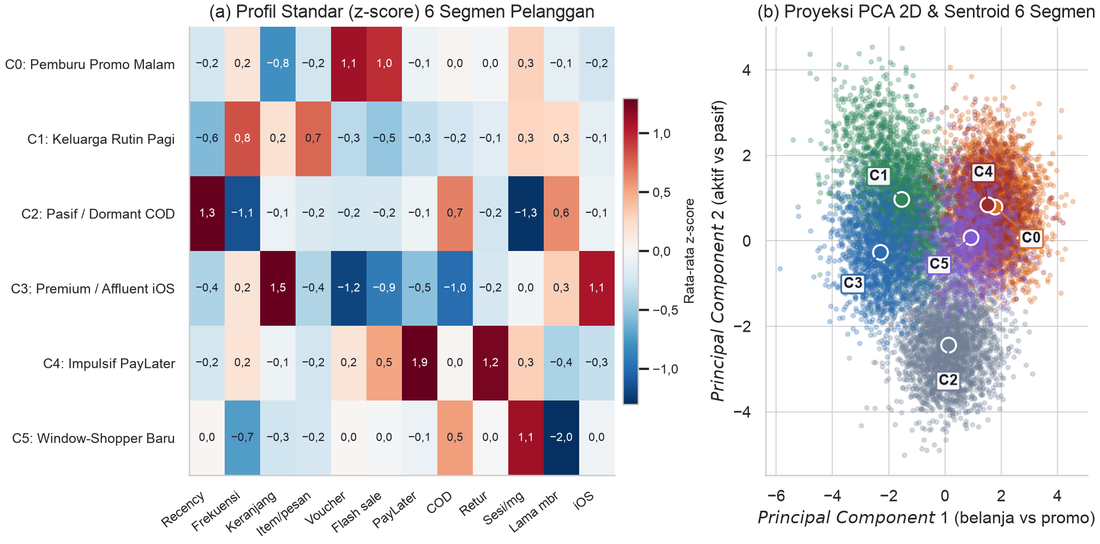

In [12]:
analisis = baca_hasil("task3_analysis.json")
profil = pd.DataFrame(analisis["segment_profiles"]).set_index("cluster")
display(profil[[
    "name", "n_customers", "pct_of_total_120k", "revenue_share_pct", "median_belanja_90h_idr",
    "median_frekuensi_90h", "median_recency_hari", "median_persen_flash_sale",
    "median_persen_paylater", "median_persen_cod", "ios_pct", "peak_time_slot",
]])
display(Markdown("**Aksi pemasaran per segmen**"))
display(profil[["name", "marketing_action"]].style.set_properties(**{"text-align": "left"}))
tampilkan_gambar("task3_3f_segment_profiles.png")

## 3g. Anomali dan Berkas `cluster.csv`

*Penanggung jawab: Rainaldi Pakpahan*

Akun bot/*click-farm* hasil deteksi 3a diberi label `-1`. Keputusannya diverifikasi dengan dua cara:
keempat indikator aktivitas memisahkan kelompok ini secara serempak, dan ekor *log-likelihood* GMM
pada pelanggan normal tidak menunjukkan populasi anomali kedua.

,nilai
n_anomalies_minus_1,1800
pct_anomalies_minus_1,1.5
bot_min_posterior,1.0
normal_max_posterior,0.0


Jumlah indikator yang menandai (0/1/4): {'0': 118161, '1': 39, '4': 1800}
Alasan: Tepat 1.800 akun (1,50%) dilabeli -1 sebagai anomali bot/click-farm karena terpisah oleh celah kosong mutlak pada 4 indikator integritas aktivitas secara serempak (44x sesi/minggu, 40x klik iklan, 17x wishlist, durasi sesi 13x lebih singkat). Ekor log-likelihood GMM pada 118.200 pelanggan sisanya naik monoton halus tanpa puncak anomali sekunder, sehingga pemangkasan kuantil tambahan dihindari agar pelanggan valid berekor berat tidak salah dilabeli -1.


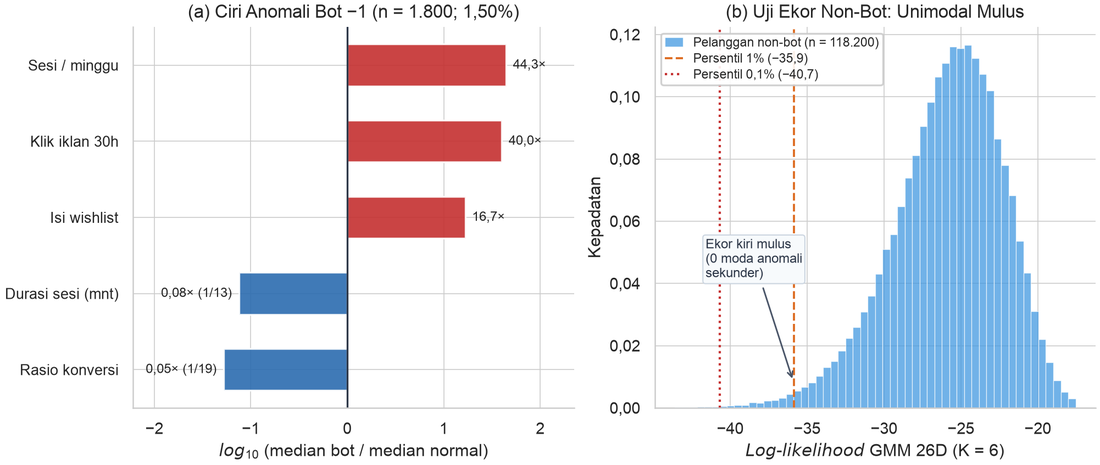

In [13]:
anomali = analisis["anomalies"]
display(pd.Series({k: anomali[k] for k in (
    "n_anomalies_minus_1", "pct_anomalies_minus_1", "bot_min_posterior", "normal_max_posterior",
)}, name="nilai", dtype=object).to_frame())
print("Jumlah indikator yang menandai (0/1/4):", anomali["four_indicator_vote_counts"])
print("Alasan:", anomali["decision_rationale"])
tampilkan_gambar("task3_3g_anomalies.png")

Pemeriksaan akhir berkas `cluster.csv` di *root* repositori: kolom, urutan ID sama dengan data
*clustering*, dan label hanya `-1` serta 0..5.

In [14]:
from src.config import CLUSTERING_PATH, PRED_CLUSTER_PATH

klaster = pd.read_csv(PRED_CLUSTER_PATH)
pelanggan = pd.read_csv(CLUSTERING_PATH, usecols=["id_pelanggan"])
assert list(klaster.columns) == ["id_pelanggan", "cluster"]
assert len(klaster) == len(pelanggan) and klaster["id_pelanggan"].equals(pelanggan["id_pelanggan"])
assert set(klaster["cluster"].unique()) <= {-1, 0, 1, 2, 3, 4, 5}
print(f"{PRED_CLUSTER_PATH.name}: {len(klaster):,} baris, kontrak terpenuhi")
display(klaster["cluster"].value_counts().sort_index().rename("jumlah").to_frame())

cluster.csv: 120,000 baris, kontrak terpenuhi


,jumlah
cluster,
-1,1800
0,29022
1,29460
2,23839
3,15092
4,11272
5,9515
